<a href="https://colab.research.google.com/github/leovarconrenno/Estacao-de-Reabastecimento-de-Hidrogenio---SCADA-Core/blob/main/etapa-03-arvores/Aula%2026%20-%20KD-Trees%20-%20code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 26 - Notebook: Indexação Multidimensional com KD-Trees no Historiador SCADA-Core

Este notebook implementa uma **KD-Tree** do zero em Python para indexar estados operacionais 4D da HRS (`PT-101`, `TT-101`, `PT-201`, `AT-101`) e realiza:
1. **Busca $k$-NN** para detecção de anomalias em tempo real;
2. **Busca por Intervalo Ortogonal** para auditoria de zonas de pré-alarme (*near-miss*);
3. **Benchmark de Desempenho** comparando KD-Tree vs. Busca Linear;
4. **Visualização do Particionamento Espacial 2D** com ponto de consulta e caixa de *range search*.

In [1]:
import time
import heapq
from typing import List, Tuple, Optional
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
np.random.seed(42)

### 1. Implementação da Estrutura KD-Tree (Construção, $k$-NN e Range Search)

In [2]:
class KDNode:
    def __init__(self, point: np.ndarray, idx: int, axis: int, left=None, right=None):
        self.point = point
        self.idx = idx
        self.axis = axis
        self.left = left
        self.right = right

class KDTree:
    def __init__(self, points: np.ndarray):
        self.k = points.shape[1]
        indexed = [(points[i], i) for i in range(len(points))]
        self.root = self._build(indexed, depth=0)

    def _build(self, items: List[Tuple[np.ndarray, int]], depth: int) -> Optional[KDNode]:
        if not items:
            return None
        axis = depth % self.k
        items.sort(key=lambda item: item[0][axis])
        mid = len(items) // 2
        pt, idx = items[mid]
        return KDNode(
            point=pt, idx=idx, axis=axis,
            left=self._build(items[:mid], depth + 1),
            right=self._build(items[mid + 1:], depth + 1),
        )

    def knn_search(self, query: np.ndarray, k_neighbors: int = 1):
        heap = []

        def _search(node: Optional[KDNode]):
            if node is None:
                return
            dist = float(np.linalg.norm(query - node.point))
            if len(heap) < k_neighbors:
                heapq.heappush(heap, (-dist, node.idx, node.point))
            elif dist < -heap[0][0]:
                heapq.heapreplace(heap, (-dist, node.idx, node.point))

            axis = node.axis
            diff = query[axis] - node.point[axis]
            first, second = (node.left, node.right) if diff <= 0 else (node.right, node.left)

            _search(first)
            if len(heap) < k_neighbors or abs(diff) < -heap[0][0]:
                _search(second)

        _search(self.root)
        return sorted([(-d, idx, pt) for d, idx, pt in heap], key=lambda x: x[0])

    def range_search(self, lower: np.ndarray, upper: np.ndarray):
        resultados = []

        def _range(node: Optional[KDNode]):
            if node is None:
                return
            if np.all((node.point >= lower) & (node.point <= upper)):
                resultados.append((node.idx, node.point))
            axis = node.axis
            if lower[axis] <= node.point[axis]:
                _range(node.left)
            if upper[axis] >= node.point[axis]:
                _range(node.right)

        _range(self.root)
        return resultados

### 2. Geração de Base Histórica da HRS ($N = 10.000$ Amostras 4D) e Consultas

In [3]:
N = 10000
# [PT-101 (bar), TT-101 (C), PT-201 (bar), AT-101 (%LIE)]
dados_brutos = np.column_stack([
    np.random.normal(340, 22, N),          # PT-101
    np.random.normal(32, 12, N),           # TT-101
    np.random.normal(720, 45, N),          # PT-201
    np.abs(np.random.normal(3.0, 2.5, N))  # AT-101
])
# Injetar 40 eventos de pre-alarme (near-miss)
dados_brutos[:40] = np.column_stack([
    np.random.uniform(375, 398, 40),
    np.random.uniform(65, 83, 40),
    np.random.uniform(820, 885, 40),
    np.random.uniform(12, 24, 40),
])

# Normalizacao por escala nominal para metrica euclidiana justa
ESCALAS = np.array([400.0, 85.0, 900.0, 25.0])
dados_norm = dados_brutos / ESCALAS

kdtree = KDTree(dados_norm)

# Consulta 1: Vetor ao vivo com anomalia incipiente
q_anomalo_raw = np.array([392.0, 78.0, 860.0, 19.0])
q_anomalo = q_anomalo_raw / ESCALAS
vizinhos = kdtree.knn_search(q_anomalo, k_neighbors=3)
print("Top-3 vizinhos históricos mais próximos da leitura ao vivo:")
for dist, idx, pt in vizinhos:
    print(f"  Idx={idx:4d} | Dist={dist:.4f} | Estado={np.round(pt * ESCALAS, 1)}")

# Consulta 2: Busca por intervalo ortogonal (Near-Miss)
lim_inf = np.array([370.0, 60.0, 800.0, 10.0]) / ESCALAS
lim_sup = np.array([400.0, 85.0, 900.0, 25.0]) / ESCALAS
near_miss = kdtree.range_search(lim_inf, lim_sup)
print(f"\nEventos de pré-alarme (near-miss) encontrados na janela 4D: {len(near_miss)}")

Top-3 vizinhos históricos mais próximos da leitura ao vivo:
  Idx=  27 | Dist=0.0328 | Estado=[391.1  75.6 855.8  18.6]
  Idx=  15 | Dist=0.0331 | Estado=[397.8  75.7 848.2  19. ]
  Idx=  22 | Dist=0.0537 | Estado=[397.   76.7 857.5  20.3]

Eventos de pré-alarme (near-miss) encontrados na janela 4D: 40


### 3. Benchmark (KD-Tree vs. Busca Linear) e Visualização de Partições 2D

200 consultas 1-NN em N=10000: KD-Tree = 37.06 ms | Linear = 134.10 ms


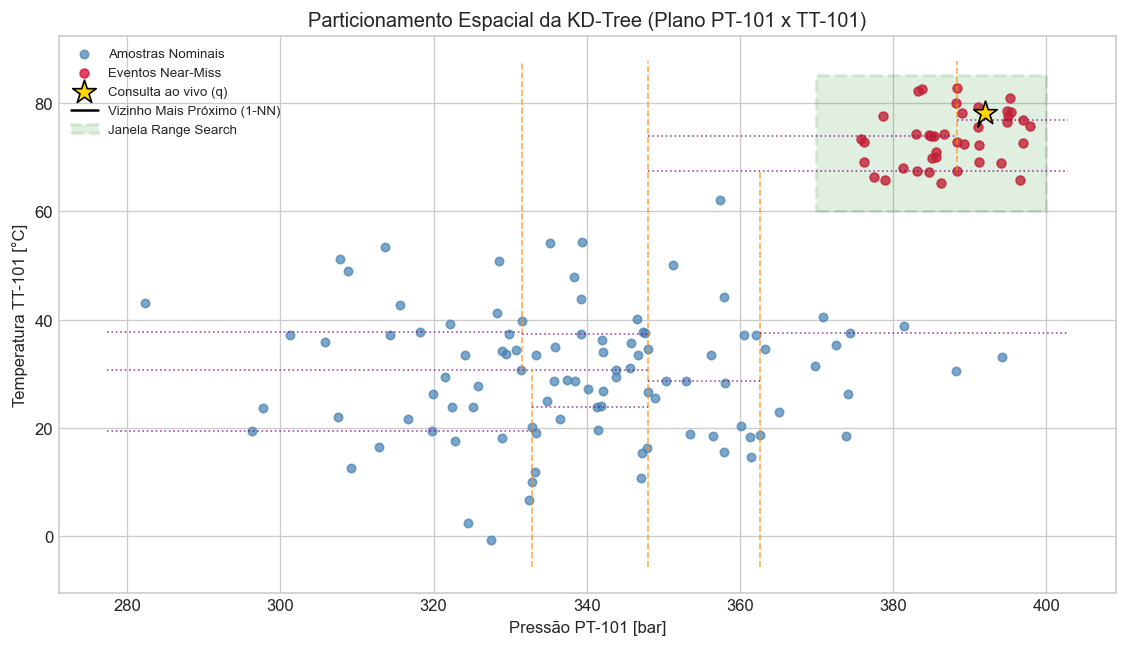

In [4]:
queries = dados_norm[:200]

t0 = time.perf_counter()
for q in queries:
    kdtree.knn_search(q, k_neighbors=1)
t_kd = (time.perf_counter() - t0) * 1000

t0 = time.perf_counter()
for q in queries:
    _ = np.argmin(np.linalg.norm(dados_norm - q, axis=1))
t_lin = (time.perf_counter() - t0) * 1000

print(f"200 consultas 1-NN em N={N}: KD-Tree = {t_kd:.2f} ms | Linear = {t_lin:.2f} ms")

# Visualizacao 2D de particionamento espacial (PT-101 vs TT-101)
pts_2d = dados_brutos[:140, :2]
kd_2d = KDTree(pts_2d)

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.scatter(pts_2d[40:, 0], pts_2d[40:, 1], c='steelblue', s=25, alpha=0.7, label='Amostras Nominais')
ax.scatter(pts_2d[:40, 0], pts_2d[:40, 1], c='crimson', s=28, alpha=0.8, label='Eventos Near-Miss')

def plot_splits(node, xmin, xmax, ymin, ymax, depth=0):
    if node is None or depth > 3:
        return
    if node.axis == 0:
        ax.plot([node.point[0], node.point[0]], [ymin, ymax], color='darkorange', linestyle='--', linewidth=1.0, alpha=0.7)
        plot_splits(node.left, xmin, node.point[0], ymin, ymax, depth + 1)
        plot_splits(node.right, node.point[0], xmax, ymin, ymax, depth + 1)
    else:
        ax.plot([xmin, xmax], [node.point[1], node.point[1]], color='purple', linestyle=':', linewidth=1.0, alpha=0.7)
        plot_splits(node.left, xmin, xmax, ymin, node.point[1], depth + 1)
        plot_splits(node.right, xmin, xmax, node.point[1], ymax, depth + 1)

plot_splits(kd_2d.root, pts_2d[:,0].min()-5, pts_2d[:,0].max()+5, pts_2d[:,1].min()-5, pts_2d[:,1].max()+5)

# Destacar consulta ao vivo e janela ortogonal
ax.scatter([q_anomalo_raw[0]], [q_anomalo_raw[1]], marker='*', s=220, c='gold', edgecolors='black', zorder=5, label='Consulta ao vivo (q)')
nn_pt = vizinhos[0][2] * ESCALAS
ax.plot([q_anomalo_raw[0], nn_pt[0]], [q_anomalo_raw[1], nn_pt[1]], color='black', linewidth=1.5, label='Vizinho Mais Próximo (1-NN)')
rect = Rectangle((370, 60), 30, 25, linewidth=2, edgecolor='green', facecolor='green', alpha=0.12, linestyle='--', label='Janela Range Search')
ax.add_patch(rect)

ax.set_title('Particionamento Espacial da KD-Tree (Plano PT-101 x TT-101)')
ax.set_xlabel('Pressão PT-101 [bar]')
ax.set_ylabel('Temperatura TT-101 [°C]')
ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()